As a culminating project, you'll be working with a dataset from ABC company,
consisting of 458 rows and 9 columns. The company requires a comprehensive
report detailing information about their employees across various teams. Your
tasks include preprocessing the dataset, analyzing the data, and presenting your
findings graphically. Here's a breakdown of what you need to do:
Preprocessing:
● Correct the data in the "height" column by replacing it with random
numbers between 150 and 180. Ensure data consistency and integrity
before proceeding with analysis. (1 mark)


In [1]:
import pandas as pd
import numpy as np

In [4]:
df=pd.read_excel('/content/ABC Company.xlsx')

In [10]:
df['Height'] = np.random.randint(150, 181, size=len(df))
print("--- Dataset Info ---")
print(df.info())

print("\n--- First 5 Rows of Updated Dataset ---")
print(df[['Name', 'Team', 'Height']].head())

df.to_excel('ABC_Company_Modified.xlsx', index=False)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    object 
 1   Team      458 non-null    object 
 2   Number    458 non-null    int64  
 3   Position  458 non-null    object 
 4   Age       458 non-null    int64  
 5   Height    458 non-null    int64  
 6   Weight    458 non-null    int64  
 7   College   374 non-null    object 
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(4), object(4)
memory usage: 32.3+ KB
None

--- First 5 Rows of Updated Dataset ---
            Name            Team  Height
0  Avery Bradley  Boston Celtics     162
1    Jae Crowder  Boston Celtics     180
2   John Holland  Boston Celtics     160
3    R.J. Hunter  Boston Celtics     167
4  Jonas Jerebko  Boston Celtics     157


1. Determine the distribution of employees across each team and calculate
the percentage split relative to the total number of employees.

In [11]:
df = pd.read_excel('ABC_Company_Modified.xlsx')

In [12]:
team_counts = df['Team'].value_counts()
total_employees = len(df)
team_percentages = (team_counts / total_employees) * 100

In [13]:
team_summary = pd.DataFrame({
    'Employee Count': team_counts,
    'Percentage (%)': team_percentages
})

In [14]:
print(team_summary)

                        Employee Count  Percentage (%)
Team                                                  
New Orleans Pelicans                19        4.148472
Memphis Grizzlies                   18        3.930131
Utah Jazz                           16        3.493450
Milwaukee Bucks                     16        3.493450
New York Knicks                     16        3.493450
Boston Celtics                      15        3.275109
Los Angeles Clippers                15        3.275109
Los Angeles Lakers                  15        3.275109
Phoenix Suns                        15        3.275109
Sacramento Kings                    15        3.275109
Brooklyn Nets                       15        3.275109
Philadelphia 76ers                  15        3.275109
Toronto Raptors                     15        3.275109
Golden State Warriors               15        3.275109
Indiana Pacers                      15        3.275109
Detroit Pistons                     15        3.275109
Cleveland 

Data Story: The dataset contains 458 employees across 30 teams. The New Orleans Pelicans has the largest number of employees, with 19 employees , followed by the Memphis Grizzlies with 18 employees.

2. Segregate employees based on their positions within the company. (2
marks)

In [15]:
position_counts = df['Position'].value_counts()
print("--- Number of Employees per Position ---")
print(position_counts)

--- Number of Employees per Position ---
Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


In [20]:
grouped_positions = df.groupby('Position')

In [23]:
for position_name, group_data in grouped_positions:
    print(f"\n==============================")
    print(f"Position: {position_name} | Total Employees: {len(group_data)}")
    print(f"==============================")


    print(group_data)


Position: C | Total Employees: 79
                Name                    Team  Number Position  Age  Height  \
7       Kelly Olynyk          Boston Celtics      41        C   25     170   
10   Jared Sullinger          Boston Celtics       7        C   24     169   
14      Tyler Zeller          Boston Celtics      44        C   26     159   
23       Brook Lopez           Brooklyn Nets      11        C   28     151   
27        Henry Sims           Brooklyn Nets      14        C   26     172   
..               ...                     ...     ...      ...  ...     ...   
439    Mason Plumlee  Portland Trail Blazers      24        C   26     158   
447      Rudy Gobert               Utah Jazz      27        C   23     154   
455     Tibor Pleiss               Utah Jazz      21        C   26     172   
456      Jeff Withey               Utah Jazz      24        C   26     151   
457         Priyanka               Utah Jazz      34        C   25     179   

     Weight         College 

Data Story : The dataset includes five positions: SG, PF, PG, SF, and C.
- SG: 102 employees
- PF: 100 employees
- PG: 92 employees
- SF: 85 employees
- C: 79 employees
Insight: SG is the most common position, while C is the least common. However, the number of employees across positions is fairly balanced.

3. Identify the predominant age group among employees.

In [24]:
age_counts = df['Age'].value_counts()

In [25]:
print("--- Employee Count by Age ---")
print(age_counts)

--- Employee Count by Age ---
Age
24    47
25    46
27    41
23    41
26    36
30    31
28    31
29    28
22    26
31    22
21    19
20    19
33    14
32    13
34    10
36    10
35     9
37     4
38     4
40     3
19     2
39     2
Name: count, dtype: int64


In [26]:
most_common_age = age_counts.idxmax()
most_common_count = age_counts.max()

In [27]:
print(f"\nThe predominant (most common) age is {most_common_age} years old, with {most_common_count} employees.")


The predominant (most common) age is 24 years old, with 47 employees.


Data Story: The predominant age group is 19–29 years, representing approximately 336 of employees.

4. Discover which team and position have the highest salary expenditure.

In [28]:
team_salaries = df.groupby('Team')['Salary'].sum()
print(team_salaries)

Team
Atlanta Hawks              72902950.0
Boston Celtics             58541068.0
Brooklyn Nets              52528475.0
Charlotte Hornets          78340920.0
Chicago Bulls              86783378.0
Cleveland Cavaliers       106988689.0
Dallas Mavericks           71198732.0
Denver Nuggets             60121930.0
Detroit Pistons            67168263.0
Golden State Warriors      88868997.0
Houston Rockets            75283021.0
Indiana Pacers             66751826.0
Los Angeles Clippers       94854640.0
Los Angeles Lakers         71770431.0
Memphis Grizzlies          76550880.0
Miami Heat                 82515673.0
Milwaukee Bucks            69603517.0
Minnesota Timberwolves     59709697.0
New Orleans Pelicans       82750774.0
New York Knicks            73303898.0
Oklahoma City Thunder      93765298.0
Orlando Magic              60161470.0
Philadelphia 76ers         30992894.0
Phoenix Suns               63445135.0
Portland Trail Blazers     48301818.0
Sacramento Kings           71683666.0
San Ant

In [29]:
highest_team = team_salaries.idxmax()
highest_team_amount = team_salaries.max()
print(f"Team with the highest salary expenditure: {highest_team} (${highest_team_amount:,.2f})")

Team with the highest salary expenditure: Cleveland Cavaliers ($106,988,689.00)


In [30]:
position_salaries = df.groupby('Position')['Salary'].sum()
highest_position = position_salaries.idxmax()
highest_position_amount = position_salaries.max()

print(f"Position with the highest salary expenditure: {highest_position} (${highest_position_amount:,.2f})")

Position with the highest salary expenditure: C ($466,377,332.00)


5. Investigate if there's any correlation between age and salary, and
represent it visually.

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
correlation = df['Age'].corr(df['Salary'])
print(f"Correlation between Age and Salary: {correlation}")

Correlation between Age and Salary: 0.21400941226570971


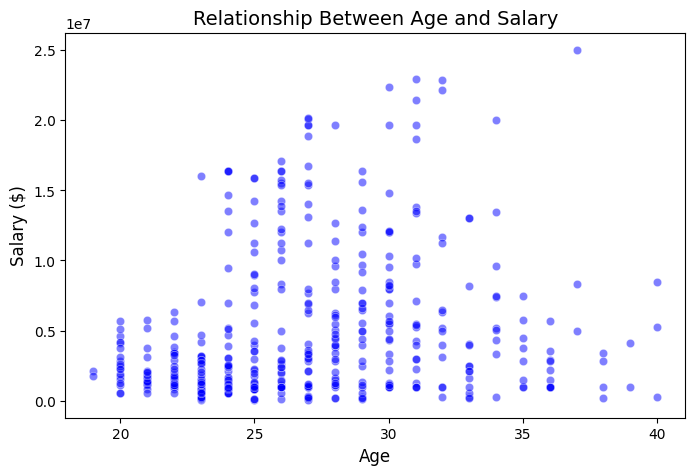

In [40]:
# 3. Create a scatter plot to visualize the relationship
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='Salary', color='blue', alpha=0.5)

# 4. Add titles and labels
plt.title('Relationship Between Age and Salary', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Salary ($)', fontsize=12)

# 5. Display the plot
plt.show()

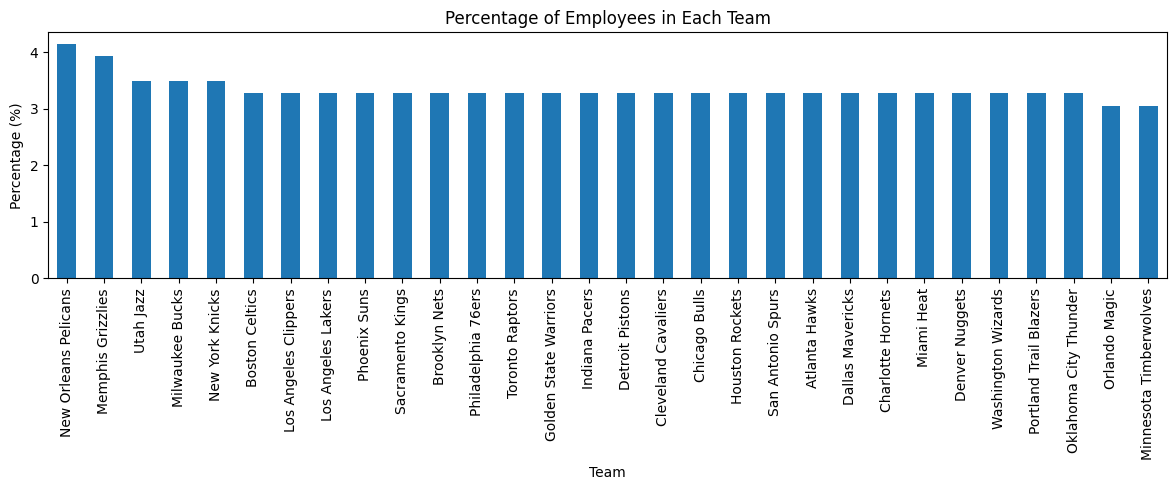

In [42]:
# Count employees in each team
team_count = df['Team'].value_counts()

# Calculate percentage
team_percentage = (team_count / len(df)) * 100

# Create a bar chart
team_percentage.plot(kind='bar', figsize=(12, 5))

plt.title('Percentage of Employees in Each Team')
plt.xlabel('Team')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Employees in each position:
Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


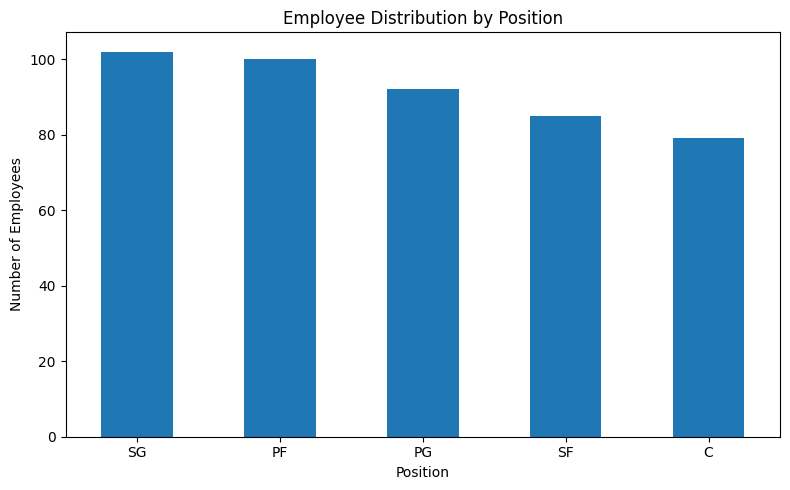

In [43]:
# Count employees in each position
position_count = df['Position'].value_counts()

print("Employees in each position:")
print(position_count)

# Create a bar chart
position_count.plot(kind='bar', figsize=(8, 5))

plt.title('Employee Distribution by Position')
plt.xlabel('Position')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Employees in each age group:
Age Group
19-29    336
30-39    119
40-49      3
Name: count, dtype: int64


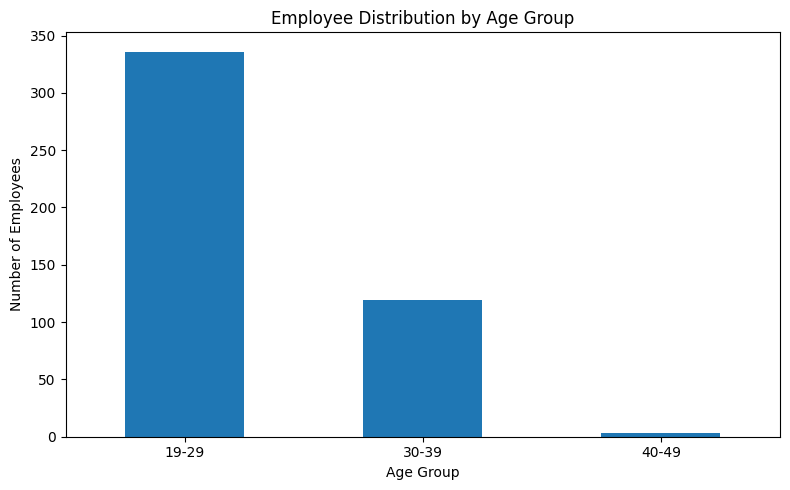

In [44]:
# Create age groups
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[18, 29, 39, 49],
    labels=['19-29', '30-39', '40-49']
)

# Count employees in each age group
age_count = df['Age Group'].value_counts().sort_index()

print("Employees in each age group:")
print(age_count)

# Create a bar chart
age_count.plot(kind='bar', figsize=(8, 5))

plt.title('Employee Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Salary expenditure by team:
Team
Cleveland Cavaliers       106988689.0
Los Angeles Clippers       94854640.0
Oklahoma City Thunder      93765298.0
Golden State Warriors      88868997.0
Chicago Bulls              86783378.0
San Antonio Spurs          84442733.0
New Orleans Pelicans       82750774.0
Miami Heat                 82515673.0
Charlotte Hornets          78340920.0
Memphis Grizzlies          76550880.0
Washington Wizards         76328636.0
Houston Rockets            75283021.0
New York Knicks            73303898.0
Atlanta Hawks              72902950.0
Los Angeles Lakers         71770431.0
Sacramento Kings           71683666.0
Dallas Mavericks           71198732.0
Toronto Raptors            71117611.0
Milwaukee Bucks            69603517.0
Detroit Pistons            67168263.0
Indiana Pacers             66751826.0
Utah Jazz                  64007367.0
Phoenix Suns               63445135.0
Orlando Magic              60161470.0
Denver Nuggets             60121930.0
Minnesota Timberw

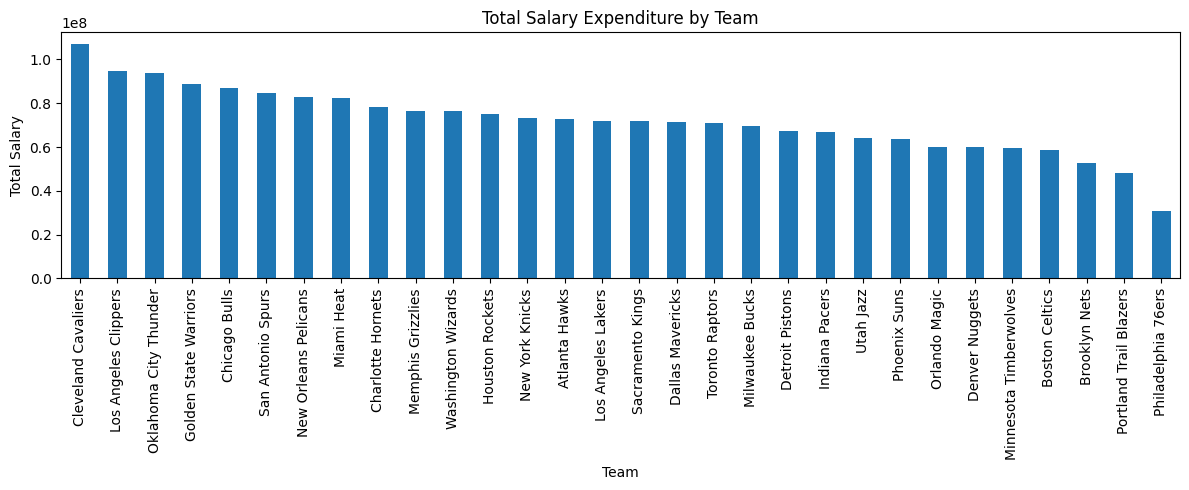

In [45]:
# Calculate total salary for each team
team_salary = df.groupby('Team')['Salary'].sum()

# Sort from highest to lowest
team_salary = team_salary.sort_values(ascending=False)

print("Salary expenditure by team:")
print(team_salary)

# Create a bar chart
team_salary.plot(kind='bar', figsize=(12, 5))

plt.title('Total Salary Expenditure by Team')
plt.xlabel('Team')
plt.ylabel('Total Salary')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Salary expenditure by position:
Position
C     466377332.0
PG    446848971.0
PF    442560850.0
SF    408020976.0
SG    396976258.0
Name: Salary, dtype: float64


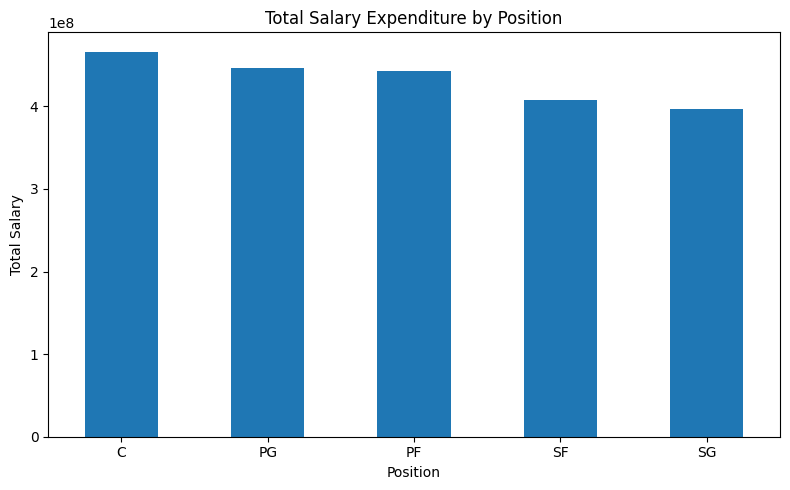

In [46]:
# Calculate total salary for each position
position_salary = df.groupby('Position')['Salary'].sum()

# Sort from highest to lowest
position_salary = position_salary.sort_values(ascending=False)

print("Salary expenditure by position:")
print(position_salary)

# Create a bar chart
position_salary.plot(kind='bar', figsize=(8, 5))

plt.title('Total Salary Expenditure by Position')
plt.xlabel('Position')
plt.ylabel('Total Salary')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Correlation between age and salary: 0.21400941226570971


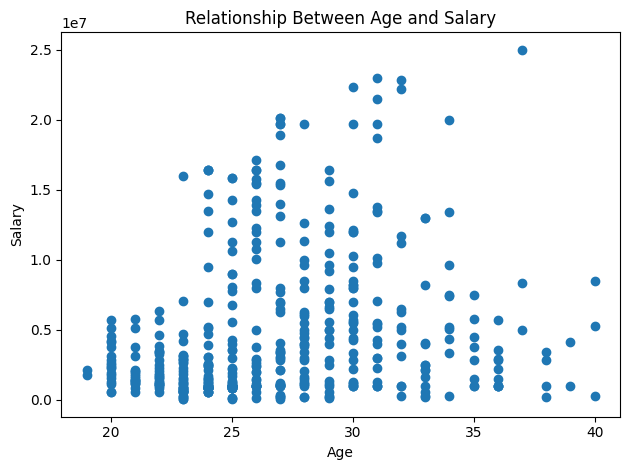

In [47]:
# Remove rows with missing age or salary
data = df.dropna(subset=['Age', 'Salary'])

# Calculate correlation
correlation = data['Age'].corr(data['Salary'])

print("Correlation between age and salary:", correlation)

# Create a scatter plot
plt.scatter(data['Age'], data['Salary'])

plt.title('Relationship Between Age and Salary')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()